<a href="https://colab.research.google.com/github/KTada777/Bayesian_SolarCell_1D_L_dep/blob/main/260725_pymc5%2Bnutpie_PVparameter_OPV_0_0003sun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!cat /proc/cpuinfo | awk '/processor/,/cpu MHz/'

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2200.202
processor	: 1
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2200.202


In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
!pip install nutpie


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.9/243.9 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 72.3 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 0.22.0
    Uninstalling arviz-0.22.0:
      Successfully uninstalled arviz-0.22.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pymc 5.28.5 requires arviz<1.0,>=0.13.0, but yo

In [ ]:
!pip install pymc
import pymc as pm
print(pm.__version__)
import arviz as az

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 20.3 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 1.2.0
    Uninstalling arviz-1.2.0:
      Successfully uninstalled arviz-1.2.0
5.28.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
import pytensor
pytensor.config.optdb__max_use_ratio = 40.0

In [ ]:
def pm_I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026    #Vt(RT)=26 mV
    x = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt

    return (V - nVt * (pm_Roberts_g(x) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def pm_Roberts_g(x):
    e_1 = np.exp(-1)
    e1 = np.exp(1)
    g = pm.math.switch((x <= -(e_1)), x, pm.math.switch((x >= e1), np.log(x), -e1 + (1 + e1) / (2 * e1) * (x + e1)))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
#
# J-V of PTB7-Th:C70 OPV @0.0003 sun.
#

X = np.array([
    0.699999, 0.69, 0.68, 0.67, 0.66, 0.65, 0.64,
    0.63, 0.62, 0.609999, 0.599999, 0.59, 0.579999, 0.569999,
    0.559999, 0.549999, 0.54, 0.53, 0.52, 0.509999, 0.499999,
    0.489999, 0.479999, 0.469999, 0.46, 0.449999, 0.44, 0.43,
    0.419999, 0.409999, 0.4, 0.389999, 0.379999, 0.37, 0.359999,
    0.35, 0.34, 0.33, 0.319999, 0.31, 0.299999, 0.289999,
    0.279999, 0.27, 0.26, 0.25, 0.24, 0.229999, 0.22,
    0.21, 0.199999, 0.189999, 0.18, 0.169999, 0.159999, 0.149999,
    0.14, 0.129999, 0.12, 0.11, 0.099999, 0.089999, 0.08,
    0.069999, 0.059999, 0.05, 0.039999, 0.029999, 0.019999, 0.01,
    -1e-06, 0.0, -0.010001, -0.020001, -0.030001, -0.04, -0.05,
    -0.060001, -0.070001, -0.080001, -0.090001, -0.1, -0.110001, -0.12,
    -0.13, -0.140001, -0.150001, -0.16, -0.170001, -0.180001, -0.190001,
    -0.2
])

Y = np.array([
    0.0011003356, 0.00088177333, 0.00069901556, 0.00054872444, 0.00042699556, 0.00032971222,
    0.00025286778, 0.00019278, 0.00014610111, 0.00011007778, 8.2401111e-05, 6.1204444e-05,
    4.4981111e-05, 3.2586667e-05, 2.3117778e-05, 1.5882222e-05, 1.034e-05, 6.1033333e-06,
    2.85e-06, 3.4777778e-07, -1.5711111e-06, -3.0622222e-06, -4.2155556e-06, -5.1211111e-06,
    -5.8333333e-06, -6.3866667e-06, -6.8355556e-06, -7.1855556e-06, -7.4655556e-06, -7.6955556e-06,
    -7.8788889e-06, -8.0322222e-06, -8.16e-06, -8.2688889e-06, -8.3588889e-06, -8.4355556e-06,
    -8.5122222e-06, -8.5744444e-06, -8.6255556e-06, -8.6811111e-06, -8.7211111e-06, -8.7711111e-06,
    -8.8077778e-06, -8.85e-06, -8.8888889e-06, -8.9222222e-06, -8.9544444e-06, -8.99e-06,
    -9.0166667e-06, -9.0511111e-06, -9.0811111e-06, -9.1055556e-06, -9.1244444e-06, -9.1555556e-06,
    -9.1788889e-06, -9.2133333e-06, -9.24e-06, -9.2644444e-06, -9.2844444e-06, -9.3022222e-06,
    -9.3311111e-06, -9.3488889e-06, -9.3677778e-06, -9.39e-06, -9.41e-06, -9.4322222e-06,
    -9.4455556e-06, -9.4722222e-06, -9.4855556e-06, -9.5011111e-06, -9.5255556e-06, -9.5244444e-06,
    -9.5366667e-06, -9.5577778e-06, -9.5711111e-06, -9.59e-06, -9.6111111e-06, -9.6233333e-06,
    -9.6388889e-06, -9.6477778e-06, -9.6666667e-06, -9.6777778e-06, -9.7e-06, -9.72e-06,
    -9.7333333e-06, -9.7422222e-06, -9.7555556e-06, -9.77e-06, -9.78e-06, -9.7955556e-06,
    -9.8155556e-06, -9.8277778e-06
])

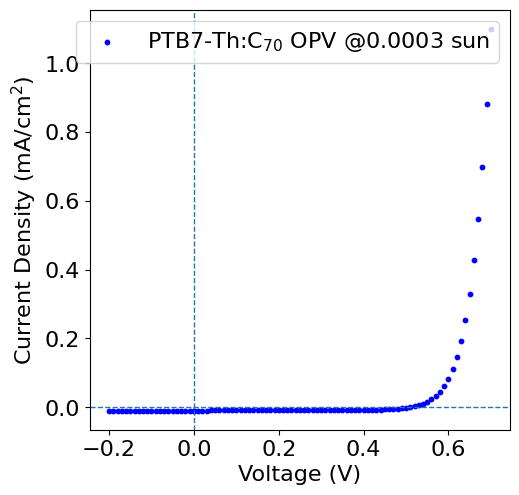

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV @0.0003 sun'
           )
#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
plt.legend()

In [ ]:
#
t0 = time.perf_counter()
#
with pm.Model() as model:
    Iph = pm.Uniform('Iph', lower=1e-4, upper=1e2 )  #mA
    Rp = pm.Uniform('Rp', lower=1e0, upper=1e8)      #Ohm
    Rs = pm.Uniform('Rs', lower=1e0, upper=1e8 )     #mOhm
    I0 = pm.Uniform('I0', lower=1e-4, upper=1e6 )    #nA
    n = pm.Uniform('n', lower=0.5, upper=500 )       #Vt(RT)=26 mV
#
    rmsd = pm.Uniform('rmsd', lower=0, upper=1e-2)
    mu = pm_I_Roberts_g(Iph, Rp, Rs, I0, n, X)
#
    y = pm.Normal('y', mu=mu, sigma=rmsd, observed=Y)
#
    trace = pm.sample(10000, tune=10000, chains=2, nuts_sampler='nutpie', target_accept=0.99)
#
t1 = time.perf_counter()
print( "elapsed time %.3f sec" % (t1-t0)  )

Progress,Draws,Divergences,Step Size,Gradients/Draw
,20000,0,0.03,63
,20000,0,0.03,175


elapsed time 754.090 sec


In [ ]:
def Roberts_g(x):
    if x <= -(np.exp(-1)):
        g = x
    elif x >= (np.exp(1)):
        g = np.log(x)
    else:
        g = -np.exp(1) + (1 + np.exp(1)) / (2 * np.exp(1)) * (x + np.exp(1))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
def I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026     #Vt(RT)=26 mV
    LogQ = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt
    return (V - nVt * (Roberts_g(LogQ) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def calcI(Iph, Rp, Rs, I0, n, V):
    V_list = V.tolist()
    I_list = [I_Roberts_g(Iph, Rp, Rs, I0, n, item) for item in V_list]
    return np.array(I_list)

In [ ]:
az.summary(trace).style.format("{:.2e}")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
I0,5.00e-03,0.00e+00,5.00e-03,6.00e-03,0.00e+00,0.00e+00,1.78e+03,1.54e+03,1.00e+00
Iph,1.00e-02,0.00e+00,9.00e-03,1.00e-02,0.00e+00,0.00e+00,1.24e+04,1.25e+04,1.00e+00
Rp,2.92e+05,1.55e+04,2.63e+05,3.21e+05,2.25e+02,1.43e+02,4.69e+03,7.20e+03,1.00e+00
Rs,9.24e+03,8.80e+01,9.07e+03,9.40e+03,2.00e+00,1.46e+00,1.95e+03,2.06e+03,1.00e+00
n,1.39e+00,2.00e-03,1.38e+00,1.39e+00,0.00e+00,0.00e+00,1.78e+03,1.52e+03,1.00e+00
rmsd,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.38e+04,1.15e+04,1.00e+00


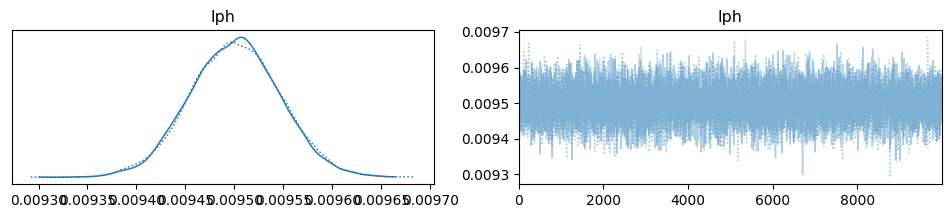

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Iph'))

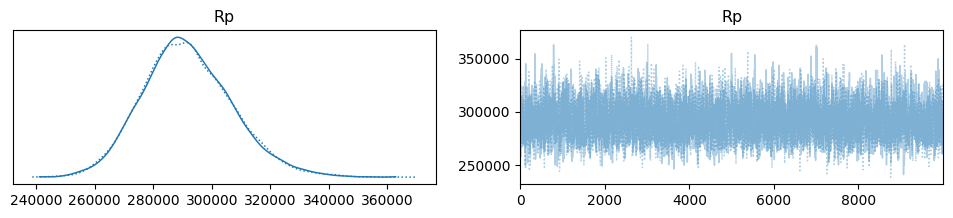

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rp'))

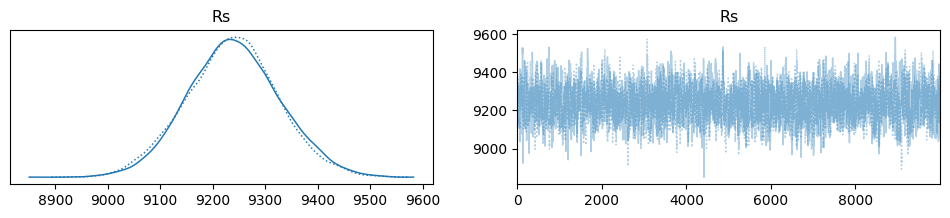

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rs'))

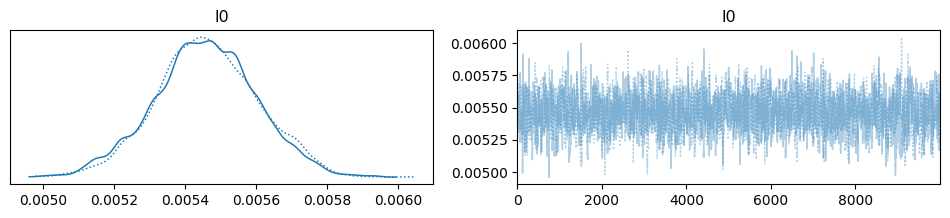

In [ ]:
with model:
  az.plot_trace(trace, var_names=('I0'))

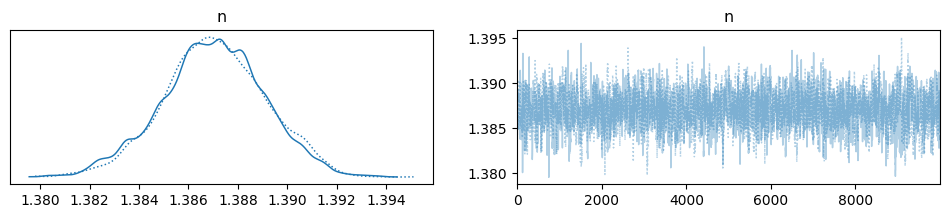

In [ ]:
with model:
  az.plot_trace(trace, var_names=('n'))

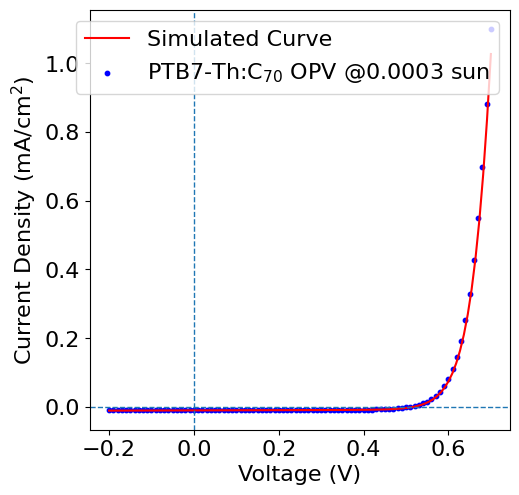

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV @0.0003 sun'
           )

xmin = np.amin(X)
xmax = np.amax(X)
N = 100
X_range = np.linspace(xmin, xmax, num=N, endpoint=True )

Q = az.summary(trace)
Iph_m = Q.loc['Iph','mean']
Rp_m = Q.loc['Rp','mean']
Rs_m = Q.loc['Rs','mean']
I0_m = Q.loc['I0','mean']
n_m = Q.loc['n','mean']
I_list = calcI(Iph_m, Rp_m, Rs_m, I0_m, n_m, X_range)

ax1.plot(X_range, I_list*1e3, color='red',
            label='Simulated Curve'
           )

#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
handles, labels = ax1.get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1])